# Feature Engineering and Principal Component Analysis (PCA)

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

The quality of input features has a significant impact on the performance of machine learning models. Feature engineering transforms raw variables into more informative predictors, while dimensionality reduction techniques help simplify complex datasets without substantial loss of information.

The objectives of this notebook are to:

- Handle structural missing values introduced during dataset merging.
- Create meaningful financial and behavioral features.
- Remove redundant and low-information variables.
- Encode categorical variables into numerical representations.
- Scale numerical features for distance-based and linear models.
- Apply Principal Component Analysis (PCA) to reduce dimensionality.
- Prepare optimized datasets for machine learning algorithms.

The transformed dataset produced in this notebook will serve as the input for all subsequent predictive modeling notebooks.

# Import Required Libraries

The following libraries are used for feature engineering, preprocessing, dimensionality reduction, and data visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.feature_selection import VarianceThreshold

from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

# Load Processed Dataset

The applicant-level dataset generated during the preprocessing stage is loaded for feature engineering and dimensionality reduction.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

merged_df = pd.read_csv(
    DATA_DIR / "credit_risk_processed.csv"
)

print("Dataset Shape:", merged_df.shape)

Dataset Shape: (307511, 362)


# Dataset Overview

Before performing feature engineering, the dimensions and data types of the processed dataset are reviewed.

In [3]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 362 entries, SK_ID_CURR to POS_SK_DPD_DEF_SUM
dtypes: float64(306), int64(41), str(15)
memory usage: 890.4 MB


# Structural Missing Value Treatment

After merging historical datasets, applicants without previous credit history contain missing values in aggregated variables such as Bureau, Previous Applications, Credit Card Balance, Installments, and POS Cash Balance.

These missing values represent the absence of historical records rather than missing information.

For aggregated numerical variables, missing values are replaced with **0**, indicating no previous activity. Categorical variables are imputed using the most frequent category.

In [4]:
# ============================================================
# Structural Missing Value Treatment
# ============================================================

numeric_cols = merged_df.select_dtypes(include=np.number).columns

categorical_cols = merged_df.select_dtypes(exclude=np.number).columns

merged_df[numeric_cols] = merged_df[numeric_cols].fillna(0)

for col in categorical_cols:

    merged_df[col] = merged_df[col].fillna(
        merged_df[col].mode()[0]
    )

print("Remaining Missing Values:",
      merged_df.isnull().sum().sum())

Remaining Missing Values: 0


# Remove Identifier Columns

Identifier variables uniquely identify applicants or previous applications but do not contain predictive information.

These variables are removed before feature engineering and machine learning.

In [5]:
# ============================================================
# Remove Identifier Columns
# ============================================================

id_columns = [
    "SK_ID_CURR"
]

merged_df.drop(
    columns=id_columns,
    inplace=True
)

print("Dataset Shape:", merged_df.shape)

Dataset Shape: (307511, 361)


# Feature Engineering

Raw financial variables often provide limited information when considered individually. Feature engineering combines existing variables to create more informative indicators that better represent an applicant's financial position and repayment capacity.

The engineered features created in this section capture:

- Debt burden
- Loan affordability
- Financing proportion
- Employment stability
- Household financial capacity
- Family dependency
- External creditworthiness

These derived variables are expected to improve the predictive performance of the machine learning models.

In [6]:
# ============================================================
# Financial Ratio Features
# ============================================================

merged_df["CREDIT_INCOME_RATIO"] = (
    merged_df["AMT_CREDIT"] /
    merged_df["AMT_INCOME_TOTAL"]
)

merged_df["ANNUITY_INCOME_RATIO"] = (
    merged_df["AMT_ANNUITY"] /
    merged_df["AMT_INCOME_TOTAL"]
)

merged_df["CREDIT_GOODS_RATIO"] = (
    merged_df["AMT_CREDIT"] /
    merged_df["AMT_GOODS_PRICE"]
)

merged_df["EMPLOYMENT_AGE_RATIO"] = (
    np.abs(merged_df["DAYS_EMPLOYED"]) /
    np.abs(merged_df["DAYS_BIRTH"])
)

merged_df["INCOME_PER_FAMILY_MEMBER"] = (
    merged_df["AMT_INCOME_TOTAL"] /
    merged_df["CNT_FAM_MEMBERS"]
)

merged_df["CHILDREN_RATIO"] = (
    merged_df["CNT_CHILDREN"] /
    merged_df["CNT_FAM_MEMBERS"]
)

print("Financial ratio features created successfully.")

Financial ratio features created successfully.


# External Credit Source Feature

The variables `EXT_SOURCE_1`, `EXT_SOURCE_2`, and `EXT_SOURCE_3` represent external credit scores obtained from independent data sources.

Instead of using each score individually, an average external credit score is computed to provide a more robust estimate of an applicant's creditworthiness.

In [7]:
# ============================================================
# External Credit Score Feature
# ============================================================

merged_df["EXT_SOURCE_MEAN"] = merged_df[
    [
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3"
    ]
].mean(axis=1)

print("External credit score feature created.")

External credit score feature created.


# Verify Newly Created Features

The newly engineered variables are inspected to ensure that they have been created successfully and contain meaningful values.

In [8]:
new_features = [
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_GOODS_RATIO",
    "EMPLOYMENT_AGE_RATIO",
    "INCOME_PER_FAMILY_MEMBER",
    "CHILDREN_RATIO",
    "EXT_SOURCE_MEAN"
]

merged_df[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
CREDIT_INCOME_RATIO,307511.0,3.957570,2.689728,0.004808,2.018667,3.265067,5.159880,8.473684e+01
ANNUITY_INCOME_RATIO,307511.0,0.180929,0.094573,0.000224,0.114782,0.162833,0.229067,1.875965e+00
CREDIT_GOODS_RATIO,307511.0,1.122542,0.125542,0.150000,1.000000,1.118800,1.198000,6.000000e+00
EMPLOYMENT_AGE_RATIO,307511.0,3.177365,6.507685,0.000000,0.068385,0.155791,0.367279,4.748966e+01
INCOME_PER_FAMILY_MEMBER,307511.0,93106.335038,101373.313820,2812.500000,47250.000000,75000.000000,112500.000000,3.900000e+07
CHILDREN_RATIO,307511.0,0.125502,0.199578,0.000000,0.000000,0.000000,0.333333,9.500000e-01
EXT_SOURCE_MEAN,307511.0,0.511503,0.108104,0.023705,0.441604,0.521564,0.587715,8.534171e-01


# Encoding Categorical Variables

Machine learning algorithms require numerical inputs. Therefore, all categorical variables are transformed into numerical representations.

Label Encoding is used because the dataset contains several categorical variables with multiple categories, and the chosen machine learning algorithms can effectively process encoded labels.

In [9]:
# ============================================================
# Label Encoding
# ============================================================

label_encoder = LabelEncoder()

categorical_columns = merged_df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:

    merged_df[column] = label_encoder.fit_transform(
        merged_df[column]
    )

print(f"Encoded {len(categorical_columns)} categorical features.")

Encoded 15 categorical features.


# Remove Low-Variance Features

Features with extremely low variance contribute little information to predictive models.

The Variance Threshold method removes such features before dimensionality reduction.

In [10]:
# ============================================================
# Remove Low Variance Features
# ============================================================

X = merged_df.drop(columns=["TARGET"])

y = merged_df["TARGET"]

selector = VarianceThreshold(
    threshold=0.01
)

X_var = selector.fit_transform(X)

selected_features = X.columns[
    selector.get_support()
]

X = pd.DataFrame(
    X_var,
    columns=selected_features
)

print("Remaining Features:", X.shape[1])

Remaining Features: 313


# Remove Highly Correlated Features

Highly correlated variables contain redundant information and may increase model complexity.

To reduce multicollinearity, one variable is removed from each pair of features with an absolute correlation greater than **0.90**.

In [11]:
# ============================================================
# Remove Highly Correlated Features
# ============================================================

corr_matrix = X.corr().abs()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

drop_columns = [
    column
    for column in upper.columns
    if any(upper[column] > 0.90)
]

X.drop(
    columns=drop_columns,
    inplace=True
)

print("Remaining Features:", X.shape[1])

Remaining Features: 207


# Feature Scaling

Principal Component Analysis is sensitive to the scale of the input variables.

Therefore, all numerical variables are standardized to have:

- Mean = 0
- Standard Deviation = 1

using the StandardScaler.

In [12]:
# ============================================================
# Standardization
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Feature Matrix Shape:", X_scaled.shape)

Scaled Feature Matrix Shape: (307511, 207)


# Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is a multivariate statistical technique used to transform a large set of correlated variables into a smaller set of uncorrelated variables called **principal components**.

The objectives of PCA are to:

- Reduce the dimensionality of the dataset.
- Eliminate redundancy caused by highly correlated features.
- Preserve the maximum possible variance.
- Improve computational efficiency for machine learning algorithms.

The standardized feature matrix obtained in the previous section serves as the input for PCA.

In [13]:
# ============================================================
# Apply PCA
# ============================================================

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("PCA completed successfully.")
print(f"Number of Principal Components: {X_pca.shape[1]}")

PCA completed successfully.
Number of Principal Components: 207


# Explained Variance Ratio

Each principal component explains a certain proportion of the total variance present in the original dataset.

The explained variance ratio helps determine how much information is retained after dimensionality reduction.

In [14]:
# ============================================================
# Explained Variance
# ============================================================

explained_variance = pd.DataFrame({
    "Principal Component": np.arange(
        1,
        len(pca.explained_variance_ratio_) + 1
    ),
    "Explained Variance": pca.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(
        pca.explained_variance_ratio_
    )
})

explained_variance.head(15)

,Principal Component,Explained Variance,Cumulative Variance
0,1,0.086874,0.086874
1,2,0.053924,0.140798
2,3,0.036939,0.177736
3,4,0.028633,0.206369
4,5,0.027155,0.233524
5,6,0.024482,0.258006
6,7,0.021891,0.279897
7,8,0.020046,0.299942
8,9,0.018153,0.318095
9,10,0.017317,0.335412


# Scree Plot

A Scree Plot visualizes the proportion of variance explained by each principal component.

The "elbow" point in the plot often indicates the number of components beyond which additional components contribute relatively little information.

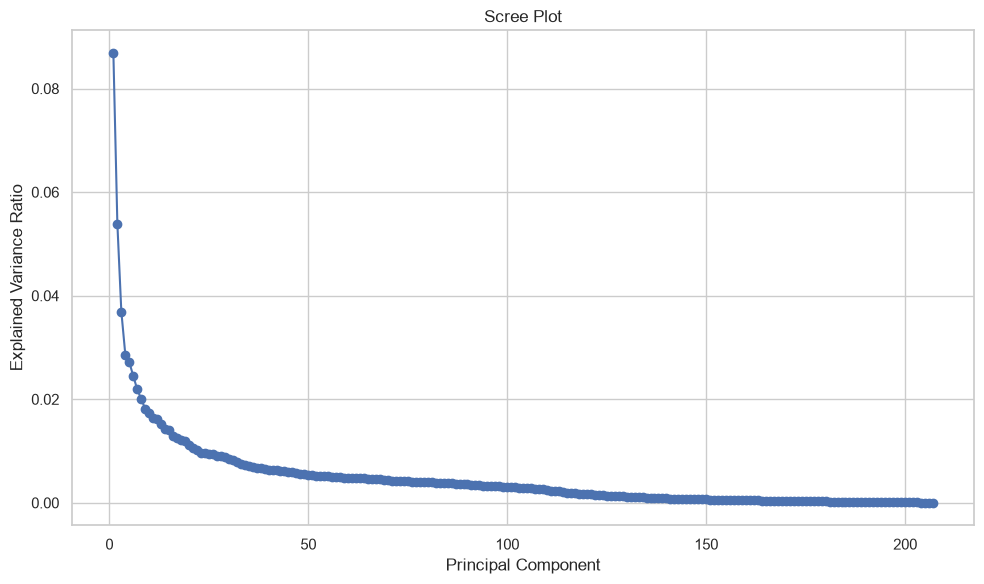

In [15]:
# ============================================================
# Scree Plot
# ============================================================

plt.figure(figsize=(10,6))

plt.plot(
    range(
        1,
        len(pca.explained_variance_ratio_) + 1
    ),
    pca.explained_variance_ratio_,
    marker="o"
)

plt.xlabel("Principal Component")

plt.ylabel("Explained Variance Ratio")

plt.title("Scree Plot")

plt.grid(True)

plt.tight_layout()

plt.show()

# Cumulative Explained Variance

The cumulative explained variance shows how much total variance is retained as additional principal components are included.

A common practice is to retain enough components to explain **95% of the total variance**.

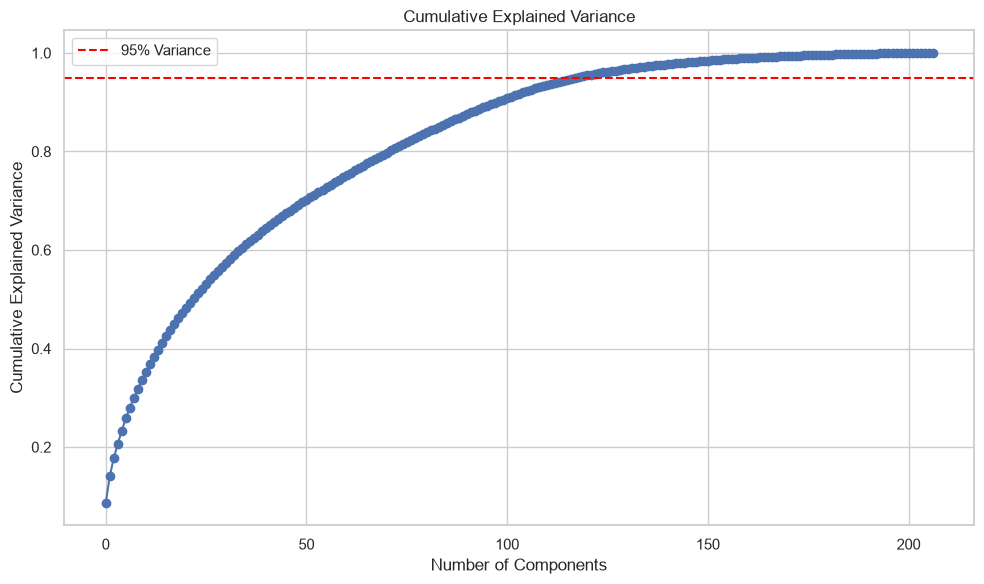

In [16]:
# ============================================================
# Cumulative Variance Plot
# ============================================================

plt.figure(figsize=(10,6))

plt.plot(
    np.cumsum(
        pca.explained_variance_ratio_
    ),
    marker="o"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% Variance"
)

plt.xlabel("Number of Components")

plt.ylabel("Cumulative Explained Variance")

plt.title("Cumulative Explained Variance")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# Determine the Optimal Number of Components

The smallest number of principal components that explains at least **95%** of the total variance is selected.

This balances dimensionality reduction with information preservation.

In [17]:
# ============================================================
# Optimal Number of Components
# ============================================================

optimal_components = np.argmax(
    np.cumsum(
        pca.explained_variance_ratio_
    ) >= 0.95
) + 1

print(
    f"Optimal Number of Components: {optimal_components}"
)

Optimal Number of Components: 119


# Transform the Dataset Using the Selected Components

The dataset is transformed using the optimal number of principal components identified in the previous step.

The resulting dataset contains only the selected principal components while retaining at least **95%** of the original variance.

In [18]:
# ============================================================
# PCA Transformation
# ============================================================

pca_final = PCA(
    n_components=optimal_components
)

X_pca_final = pca_final.fit_transform(
    X_scaled
)

pca_columns = [
    f"PC{i}"
    for i in range(
        1,
        optimal_components + 1
    )
]

pca_df = pd.DataFrame(
    X_pca_final,
    columns=pca_columns
)

# Add Target Variable
pca_df["TARGET"] = y.values

print("Final PCA Dataset Shape:", pca_df.shape)

pca_df.head()

Final PCA Dataset Shape: (307511, 120)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47,PC48,PC49,PC50,PC51,PC52,PC53,PC54,PC55,PC56,PC57,PC58,PC59,PC60,PC61,PC62,PC63,PC64,PC65,PC66,PC67,PC68,PC69,PC70,PC71,PC72,PC73,PC74,PC75,PC76,PC77,PC78,PC79,PC80,PC81,PC82,PC83,PC84,PC85,PC86,PC87,PC88,PC89,PC90,PC91,PC92,PC93,PC94,PC95,PC96,PC97,PC98,PC99,PC100,PC101,PC102,PC103,PC104,PC105,PC106,PC107,PC108,PC109,PC110,PC111,PC112,PC113,PC114,PC115,PC116,PC117,PC118,PC119,TARGET
0,-2.939164,0.053170,1.214106,1.483600,-0.245309,1.264384,-0.296942,3.662867,-5.266541,-0.600725,-0.229354,-0.055178,0.215465,1.058631,0.692587,0.169204,1.052854,0.580388,-0.597633,-2.794888,-1.770621,-1.279555,5.426133,2.967059,0.499533,0.675956,0.374692,-0.883709,0.432383,-0.016250,0.589817,1.583357,-0.172681,-0.147196,-0.994299,-0.242312,-0.292315,-0.430246,-1.646738,0.214446,-0.836652,-1.016743,0.613631,0.089011,0.869938,-0.083649,-0.723761,-0.382742,0.024321,0.210078,-0.058039,0.289367,-0.491960,-0.309883,-0.904832,-0.002995,0.358875,0.436506,0.156163,0.985279,0.283073,0.788200,0.139121,-0.664186,-0.606157,0.757034,0.711806,-0.721902,0.388632,1.295861,-1.430651,-1.022914,-0.750977,0.753920,-1.099906,-1.086122,-1.135981,-0.742415,0.255522,0.665061,-1.830132,1.032018,-0.547497,-0.213907,0.141768,-0.321594,-0.387710,0.139563,0.090693,-0.028893,0.134938,-0.290628,-0.256600,-0.169351,0.828785,-0.341399,-0.143169,0.104873,0.394160,1.309396,0.516881,-1.050470,0.075201,-1.144720,-0.657256,-0.411475,0.299649,-0.130432,-0.361141,0.082307,-0.414862,-0.021142,-0.061371,0.535889,0.720087,0.876707,-0.200228,0.688970,-0.025785,1
1,0.684791,3.968772,-0.781480,2.412060,-3.221174,0.022428,-0.640647,-2.404843,0.807254,0.899715,-0.484537,-0.824822,0.667419,-0.592195,-5.117921,-1.278692,-1.894581,0.062762,1.668848,-0.439093,2.834071,-0.508623,-1.119157,4.209469,-0.630099,10.504663,-1.290244,-0.404071,-2.737252,0.625786,-2.355622,0.152962,0.200295,-0.638092,0.165689,0.137221,-0.170575,-0.038872,-0.031924,0.370163,0.338653,0.896817,-0.386820,0.344287,-0.349752,-0.212865,0.076604,0.211792,-0.506242,0.331123,0.034300,0.420537,0.407335,0.189817,0.993363,-0.902445,-0.975983,-0.036547,-0.917874,-3.215781,-1.748418,1.200018,0.814881,1.428845,1.057136,-2.093452,-3.486476,0.559090,0.114862,1.681742,-0.682397,-0.465973,0.538345,-1.158240,2.731334,-2.198628,-4.676305,0.960294,0.762618,-1.478290,-0.198636,1.824589,-0.565746,-0.092100,-0.320398,-0.509761,0.446462,0.258894,1.957230,-1.591716,-0.260183,0.929558,0.960875,1.675369,0.791631,0.017815,0.303163,1.331938,0.870379,0.324762,1.532985,-0.161075,0.142136,0.417873,-0.502720,-0.532929,0.435183,0.076465,-0.707633,0.067790,-0.054801,0.643008,0.053076,0.228622,-0.315865,0.608695,-0.411565,0.555230,0.071973,0
2,-4.558158,-1.922306,-0.692991,-1.024337,0.022295,0.288032,0.842006,-1.481679,0.315637,0.881984,0.342582,-0.327507,-0.491488,1.071858,0.675816,0.422463,-0.773248,-0.431168,-1.352521,0.931504,0.598907,-2.237298,-0.732159,-0.339030,0.099529,-0.015637,-0.057860,-0.325745,-0.385160,-0.109704,2.560432,-0.755042,0.071739,-1.008510,-0.896911,0.257199,0.117797,0.599365,-1.745575,-1.106614,-0.779769,-1.033622,0.889196,0.376735,-1.629655,-0.330522,1.413932,-0.328060,-0.559024,0.019589,0.622755,1.349363,-0.210868,-0.137152,0.423068,-0.219783,-0.052074,-0.127507,0.005937,0.143370,-0.349587,-0.941923,-0.243920,-0.707974,-0.479815,-0.265106,-0.271158,-0.224983,-0.087970,-0.588837,0.720660,-0.589582,0.234158,0.827019,-0.589839,-0.151801,-0.837514,0.439709,-0.211979,-0.233620,-0.809521,-0.164494,-0.403132,0.671556,0.074054,0.126111,0.494260,-0.480445,-0.300472,0.058549,0.095683,0.050381,-0.623472,-0.113878,0.706108,-0.668506,-0.014399,0.240861,-0.038230,0.227447,-0.003297,-0.274059,-0.136160,0.737115,-0.130014,0.053699,0.720967,0.989039,0.608096,-0.125012,-0.262509,0.031380,0.135972,-0.589268,-0.558771,0.371974,-0.35

# Save the PCA Dataset

The transformed dataset is saved for use in subsequent machine learning notebooks.

Using the same PCA-transformed dataset ensures that all classification models are trained and evaluated on a consistent feature space.

In [19]:
# ============================================================
# Save PCA Dataset
# ============================================================

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pca_df.to_csv(
    OUTPUT_DIR / "credit_risk_pca.csv",
    index=False
)

print("PCA dataset saved successfully.")
print(f"Dataset Shape: {pca_df.shape}")

PCA dataset saved successfully.
Dataset Shape: (307511, 120)


# Publication Upgrade: Parallel Non-PCA Feature Track

## Why a second, non-PCA feature set is needed

The PCA-transformed dataset (`credit_risk_pca.csv`) is excellent for training compact,
decorrelated models, but the resulting features (`PC1`, `PC2`, ...) are linear blends of
dozens of original variables each. They cannot be shown to a credit officer, a regulator,
or a journal reviewer as "the reason this applicant was scored as high-risk" — an SHAP
value on `PC7` is not an actionable statement.

To support **Explainable AI (SHAP)** and **business interpretation** with real feature
names, while keeping the existing PCA modeling pipeline completely unchanged, this
section saves a second, parallel train/test split built from `X` — the same
variance-filtered, correlation-filtered, encoded feature matrix that feeds PCA, but
**before scaling and before dimensionality reduction**. Tree-based models (Random
Forest, XGBoost, LightGBM) do not require feature scaling, so this unscaled matrix can
be used directly for SHAP explainability and for a **PCA vs. Non-PCA benchmark** in
Notebook 13 — a direct, low-cost research novelty contribution: does dimensionality
reduction cost predictive performance on this dataset, and how much interpretability is
gained in return?

The same `random_state=42` and the same stratification target are used as in the
existing PCA train-test split later in this notebook, which guarantees (and is verified
below) that both tracks contain **the exact same applicants** in their respective
train/test partitions — so results from the two tracks are directly comparable
applicant-for-applicant.

In [20]:
# ============================================================
# Save Parallel Non-PCA Train/Test Split (for SHAP & Non-PCA Benchmark)
# ============================================================

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Non-PCA Training Features :", X_train_full.shape)
print("Non-PCA Testing Features  :", X_test_full.shape)

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X_train_full.to_csv(OUTPUT_DIR / "X_train_full.csv", index=False)
X_test_full.to_csv(OUTPUT_DIR / "X_test_full.csv", index=False)
y_train_full.to_csv(OUTPUT_DIR / "y_train_full.csv", index=False)
y_test_full.to_csv(OUTPUT_DIR / "y_test_full.csv", index=False)

print("Non-PCA train/test split saved successfully.")
print(f"Non-PCA feature count: {X_train_full.shape[1]} (named, unscaled features)")

Non-PCA Training Features : (246008, 207)
Non-PCA Testing Features  : (61503, 207)


Non-PCA train/test split saved successfully.
Non-PCA feature count: 207 (named, unscaled features)


# Save PCA Loading Matrix (Component Interpretation)

Even within the primary PCA pipeline, it is possible to partially recover business
meaning from an important principal component by inspecting its **loadings** — the
weight each original feature contributes to that component.

The full loading matrix (`components_` from the fitted `pca_final` estimator) is saved
here with the original, named features as rows and principal components as columns.
Later notebooks can look up, for example, "PC7" and report the top 5 original features
driving it (e.g., `EXT_SOURCE_2`, `DAYS_EMPLOYED`, `AMT_CREDIT`), giving a secondary,
loading-based interpretation path that complements the SHAP-on-non-PCA-features
approach above.

In [21]:
# ============================================================
# Save PCA Loading Matrix
# ============================================================

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pca_loadings = pd.DataFrame(
    pca_final.components_.T,
    index=X.columns,
    columns=pca_columns
)

pca_loadings.to_csv(RESULTS_DIR / "pca_loadings.csv")

print("PCA loading matrix saved to: ../results/pca_loadings.csv")
print("Shape (original features x components):", pca_loadings.shape)

# Preview: top 5 original features driving the first 3 principal components
for component in pca_columns[:3]:
    top_features = pca_loadings[component].abs().sort_values(ascending=False).head(5)
    print(f"\nTop contributing features for {component}:")
    print(top_features)

PCA loading matrix saved to: ../results/pca_loadings.csv
Shape (original features x components): (207, 119)

Top contributing features for PC1:
INST_AMT_INSTALMENT_SUM            0.175719
CC_AMT_DRAWINGS_CURRENT_MAX        0.175663
CC_AMT_CREDIT_LIMIT_ACTUAL_SUM     0.172453
CC_AMT_DRAWINGS_CURRENT_SUM        0.168071
CC_AMT_DRAWINGS_ATM_CURRENT_MAX    0.161043
Name: PC1, dtype: float64

Top contributing features for PC2:
PREV_DAYS_FIRST_DRAWING_MIN        0.180361
PREV_DAYS_FIRST_DRAWING_MEAN       0.171752
INST_NUM_INSTALMENT_VERSION_MIN    0.167963
PREV_CNT_PAYMENT_MEAN              0.162210
PREV_CNT_PAYMENT_MAX               0.149215
Name: PC2, dtype: float64

Top contributing features for PC3:
BUREAU_DAYS_CREDIT_MEAN           0.257840
BUREAU_DAYS_CREDIT_MIN            0.249006
BUREAU_DAYS_ENDDATE_FACT_MIN      0.238928
BUREAU_DAYS_ENDDATE_FACT_MEAN     0.236340
BUREAU_DAYS_CREDIT_UPDATE_MEAN    0.233797
Name: PC3, dtype: float64


# Reproducibility: Environment & Random Seed Report

Journal reviewers and future re-implementers need to know exactly which package
versions and random seeds produced the reported results. A single `RANDOM_STATE = 42`
is used consistently for every stratified split, cross-validation fold, and stochastic
model in this project (Notebooks 05–15). The cell below records the installed package
versions used to generate the project's results and writes them to
`results/environment_report.txt` alongside the fixed seed, so the full computational
environment can be reported in the paper's Methods/Reproducibility section or an
appendix.

In [22]:
# ============================================================
# Environment & Reproducibility Report
# ============================================================

import sys
import platform
import importlib
from datetime import datetime

PACKAGES = [
    "numpy", "pandas", "scipy", "matplotlib", "seaborn",
    "sklearn", "xgboost", "lightgbm", "joblib", "shap", "fairlearn",
]

lines = [
    "Credit Risk Scoring System - Environment & Reproducibility Report",
    "=" * 68,
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    f"Python: {sys.version.split()[0]}",
    f"Platform: {platform.platform()}",
    "",
    "Fixed random seed used throughout (splits, CV folds, stochastic models): 42",
    "",
    "Package versions:",
]

for package in PACKAGES:
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "unknown")
        lines.append(f"  {package:<12} {version}")
    except ImportError:
        lines.append(f"  {package:<12} NOT INSTALLED (required for SHAP/fairness notebooks - "
                      f"run: pip install {package})")

report_text = "\n".join(lines)
print(report_text)

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(RESULTS_DIR / "environment_report.txt", "w", encoding="utf-8") as f:
    f.write(report_text + "\n")

print("\nEnvironment report saved to: ../results/environment_report.txt")

Credit Risk Scoring System - Environment & Reproducibility Report
Generated: 2026-08-30T12:47:19
Python: 3.13.14
Platform: Windows-11-10.0.26200-SP0

Fixed random seed used throughout (splits, CV folds, stochastic models): 42

Package versions:
  numpy        2.4.6
  pandas       3.0.5
  scipy        1.18.0
  matplotlib   3.11.1
  seaborn      0.13.2
  sklearn      1.9.0
  xgboost      3.3.0
  lightgbm     4.7.0
  joblib       1.5.3
  shap         0.52.0
  fairlearn    0.14.0

Environment report saved to: ../results/environment_report.txt


# Conclusion

This notebook transformed the processed applicant-level dataset into an optimized feature space suitable for predictive modeling.

The following tasks were successfully completed:

- Structural missing values were handled.
- Domain-specific financial features were engineered.
- Identifier columns were removed.
- Categorical variables were encoded.
- Low-variance and highly correlated features were eliminated.
- Features were standardized.
- Principal Component Analysis (PCA) was applied for dimensionality reduction.
- An optimal number of principal components was selected based on the cumulative explained variance.
- The PCA-transformed dataset was saved for subsequent machine learning models.

The resulting dataset provides a compact and information-rich representation of applicant characteristics while preserving the majority of the original variance. This transformed dataset will be used to train and evaluate multiple classification algorithms, including Logistic Regression, Decision Tree, K-Nearest Neighbors, Naïve Bayes, Random Forest, XGBoost, and LightGBM.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 06 – Logistic Regression**

# Train-Test Split

Before training machine learning models, the PCA-transformed dataset is divided into training and testing subsets.

A **stratified train-test split** is used to preserve the proportion of default and non-default applicants in both datasets. This is particularly important because the Home Credit dataset exhibits class imbalance.

The split configuration used throughout this project is:

- **Training Set:** 80%
- **Testing Set:** 20%
- **Random State:** 42
- **Stratification:** Based on the target variable (`TARGET`)

Using the same training and testing sets for all classification models ensures a fair and reproducible comparison of model performance.

In [23]:
# ============================================================
# Train-Test Split
# ============================================================

from sklearn.model_selection import train_test_split

X = pca_df.drop(columns=["TARGET"])
y = pca_df["TARGET"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Feature Matrix :", X_train.shape)
print("Testing Feature Matrix  :", X_test.shape)

print("Training Labels         :", y_train.shape)
print("Testing Labels          :", y_test.shape)

Training Feature Matrix : (246008, 119)
Testing Feature Matrix  : (61503, 119)
Training Labels         : (246008,)
Testing Labels          : (61503,)


# Verify Class Distribution

To ensure that stratified sampling has been performed correctly, the class distribution of the training and testing datasets is compared.

A similar proportion of default and non-default applicants in both subsets confirms that the train-test split has preserved the original class distribution.

In [24]:
# ============================================================
# Class Distribution
# ============================================================

train_distribution = (
    y_train.value_counts(normalize=True)
    .rename("Training")
)

test_distribution = (
    y_test.value_counts(normalize=True)
    .rename("Testing")
)

distribution = pd.concat(
    [train_distribution, test_distribution],
    axis=1
)

distribution

,Training,Testing
TARGET,,
0,0.919271,0.919272
1,0.080729,0.080728


# Save the Training and Testing Datasets

The PCA-transformed training and testing datasets are saved separately.

These datasets will be loaded directly in all subsequent machine learning notebooks, ensuring that every classification algorithm is trained and evaluated using the same data partitions.

This approach guarantees consistency, reproducibility, and a fair comparison of model performance.

In [25]:
# ============================================================
# Save Train-Test Split
# ============================================================

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X_train.to_csv(OUTPUT_DIR / "X_train.csv", index=False)
X_test.to_csv(OUTPUT_DIR / "X_test.csv", index=False)

y_train.to_csv(OUTPUT_DIR / "y_train.csv", index=False)
y_test.to_csv(OUTPUT_DIR / "y_test.csv", index=False)

print("Training and testing datasets saved successfully.")

Training and testing datasets saved successfully.


# Verify Non-PCA / PCA Track Alignment

Both the PCA train-test split above and the non-PCA train-test split saved earlier in
this notebook used `train_test_split(..., random_state=42, stratify=<TARGET>)` on
data of identical length and identical target ordering. Because `train_test_split`'s
stratified shuffling depends only on the label array and the random seed — not on the
feature matrix passed in — this guarantees the two splits select the **same row
indices**. The check below confirms this explicitly, so any downstream analysis that
combines PCA-model predictions with non-PCA SHAP explanations (Notebooks 12 and 13) is
guaranteed to be comparing the same applicants.

In [26]:
# ============================================================
# Verify Alignment Between PCA and Non-PCA Splits
# ============================================================

y_train_check = y_train.reset_index(drop=True)
y_train_full_check = y_train_full.reset_index(drop=True)

y_test_check = y_test.reset_index(drop=True)
y_test_full_check = y_test_full.reset_index(drop=True)

train_aligned = y_train_check.equals(y_train_full_check)
test_aligned = y_test_check.equals(y_test_full_check)

print("Train split target alignment (PCA vs Non-PCA):", train_aligned)
print("Test split target alignment  (PCA vs Non-PCA):", test_aligned)

assert train_aligned and test_aligned, (
    "PCA and Non-PCA splits are misaligned - downstream SHAP/model comparisons "
    "would not refer to the same applicants."
)

print("\nBoth tracks are row-aligned. Safe to compare PCA-model and "
      "Non-PCA-model results applicant-for-applicant.")

Train split target alignment (PCA vs Non-PCA): True
Test split target alignment  (PCA vs Non-PCA): True

Both tracks are row-aligned. Safe to compare PCA-model and Non-PCA-model results applicant-for-applicant.


# Save the Complete PCA Dataset

In addition to the train-test split, the complete PCA-transformed dataset is also saved.

This dataset serves as a consolidated record of the dimensionality reduction process and can be used for further exploratory analysis, visualization, or future experimentation.

In [27]:
# ============================================================
# Save PCA Dataset
# ============================================================

pca_df.to_csv(
    OUTPUT_DIR / "credit_risk_pca.csv",
    index=False
)

print("PCA dataset saved successfully.")
print(f"Dataset Shape: {pca_df.shape}")

PCA dataset saved successfully.
Dataset Shape: (307511, 120)
